In [1]:
from ray_tracing_init import *
%matplotlib widget


In [39]:
def cart_conv(sph_coord):

    r_a  = sph_coord[1]
    th_a = sph_coord[2]
    phi_a = sph_coord[3]
    t_a = sph_coord[0]

    z_a = r_a * np.sin(th_a) * np.cos(phi_a) 
    x_a = r_a * np.sin(th_a) * np.sin(phi_a)
    
    y_a = r_a * -np.cos(th_a)
    
    return [x_a,y_a,z_a,t_a]

def solve_geod(t0,r0,theta0,phi0,rd0,thetad0,phid0, reverse = 1, lam_max = 1000, n_lam = 1000):

    td0 = null_curve(r0, theta0, [rd0,thetad0,phid0])
    coord0 = [t0,r0,theta0,phi0,td0,rd0,thetad0,phid0]

    lam0 = 0
    lam_space=np.linspace(lam0,reverse*lam_max,n_lam)

    horizon.terminal = True

    sol = solve_ivp(
        geod,
        [lam_space[0], lam_space[-1] ],
        coord0,
        method='DOP853', #method to 8th order
        rtol=1e-10, atol=1e-12, #smaller tolerance for best accuracy
        t_eval = lam_space,
        events = horizon
    )

    t_a,r_a,th_a,phi_a,td_a,rd_a,thd_a,phid_a = sol.y

    
    return [t_a,r_a,th_a,phi_a]


geo_vec = np.vectorize(solve_geod, otypes=[object])


In [45]:
#Black hole
m_val = 5

#SCREEN (coordinates on screen plane)
screen_dist = -5000

x_screen = np.linspace(-5,5,4)*m_val
rho = 0

#INITIAL COORDINATES IN SPACE
z0 = screen_dist
y0 = 0
r0 = np.sqrt(x_screen**2 + z0**2)
theta0 = np.pi/2
phi0 = np.arctan2(x_screen,z0)
t0 = 0

#INITIAL SPEEDS
zd0 = -10
yd0 = 0
xd0 = 0

rd0 = (1/r0)*(x_screen*xd0 + y0*yd0 + z0*zd0)
phid0 = (z0*xd0 - x_screen*zd0)/(x_screen**2+z0**2)
thetad0 = (((x_screen**2 + z0**2)*yd0 - y0*(x_screen*xd0 + z0*zd0))/
           (np.sqrt(x_screen**2 + z0**2)*(x_screen**2+y0**2+z0**2)))


#Computing geodesics
geos_sph = geo_vec(t0,r0,theta0,phi0,rd0,thetad0,phid0, reverse = -1, lam_max = 2000, n_lam = 3000)
geos = [cart_conv(i) for i in geos_sph]

In [42]:
rho_space = np.linspace(0,np.pi,5)

#CREATING SCREEN GRID

R,RHO = np.meshgrid(x_screen,rho_space)

GEOD = np.full(R.shape, None, dtype=object)

for i in range(len(rho_space)):
    for j in range(len(x_screen)):
        geosx = geos[j][0]*np.cos(rho_space[i])
        geosy = geos[j][0]*np.sin(rho_space[i])
        geosz = geos[j][2]
        geost = geos[j][3]
        GEOD[i][j] = [geosx,geosy,geosz,geost]

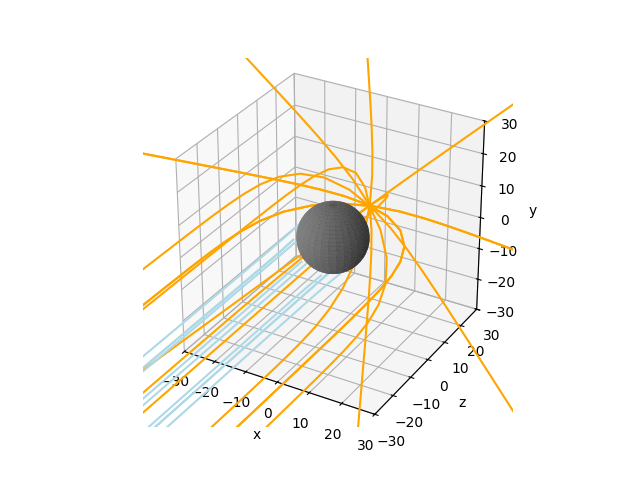

In [43]:
plotter_3d(GEOD.flat)

In [ ]:
def azimut_sweep(geod_sph):
    
    r_a  = geod_sph[1]
    th_a = geod_sph[2]
    phi_a = geod_sph[3]
    
    y0 = r_a[0] * -np.cos(th_a[0])
    x0 = r_a[0] * np.sin(th_a[0]) * np.sin(phi_a[0])

    b = np.linalg.norm([x0,y0])

    R = 1 - b**2/r_a**2 * (1 - 2*m_val/r_a)
    integrand = b/r_a**2*1/np.sqrt(R)

    phi_sweep = np.trapezoid(integrand, x = r_a)

    return phi_sweep

for i in GEOD:
    print(i.shape())

In [ ]:
Td = np.full(R.shape, None, dtype=object)

for i in range(len(rho_space)):
    for j in range(len(x_screen)):
        Td[i][j] = x_screen[j] * azimut_sweep(GEOD[i][j])